In [111]:
import torch
import whisper
from torch import nn
from whisper.model import LayerNorm, Linear, MultiHeadAttention, ResidualAttentionBlock, TextDecoder

torch.set_default_dtype(torch.float16)
model = whisper.load_model('large-v3-turbo')

In [186]:
import numpy as np
from onnx import TensorProto, numpy_helper
from onnx.checker import check_model
from onnx.helper import (
    find_min_ir_version_for,
    make_graph,
    make_model,
    make_node,
    make_opsetid,
    make_tensor_value_info,
)


def initializer(name: str, ref):
    if isinstance(ref, torch.Tensor):
        ref = ref.detach().numpy()
    elif isinstance(ref, np.ndarray):
        pass
    else:
        raise TypeError(f"ref for initializer {name} is of unknown type")
    initializers.append(numpy_helper.from_array(ref, name=name))
    return name

def node(name: str, type: str, inputs: list[str], outputs: list[str] | None = None, **kwargs):
    if outputs is None:
        outputs = [f"{name}.out"]
    nodes.append(make_node(type, inputs, outputs, name=name, **kwargs))
    if len(outputs) == 1:
        outputs = outputs[0]
    return outputs

def input(name: str, type: int, dims: list):
    inputs.append(make_tensor_value_info(name, type, dims))
    return name

def output(name: str, type: int, dims: list):
    outputs.append(make_tensor_value_info(name, type, dims))
    return name

def value_info(name: str, type: int, dims: list):
    value_infos.append(make_tensor_value_info(name, type, dims))
    return name

def linear(name: str, ref: Linear, x: str):
    weight = initializer(f'{name}.weight', ref.weight.T)
    x = node(f"{name}.mul", "MatMul", [x, weight])
    if ref.bias is None:
        return x
    else:
        bias = initializer(f"{name}.bias", ref.bias)
        return node(f"{name}.add", "Add", [x, bias])

def multi_head_attention(name: str, ref: MultiHeadAttention, x: str, cross_kv: tuple[str, str] = None):
    q = linear(f"{name}.query", ref.query, x)
    if cross_kv is not None:
        k, v = cross_kv
        inputs = inputs_ms = [q, k, v]
    else:
        k = linear(f"{name}.key", ref.key, x)
        v = linear(f"{name}.value", ref.value, x)

        past_key = input(f"past.{name}.key", TensorProto.FLOAT16, ["self_kv_cache_width", "num_heads", "past_sequence_length", "head_size"])
        past_key = node(f"{name}.past_key_gather", "Gather", [past_key, "self_kv_cache_indices"])
        past_value = input(f"past.{name}.value", TensorProto.FLOAT16, ["self_kv_cache_width", "num_heads", "past_sequence_length", "head_size"])
        past_value = node(f"{name}.past_value_gather", "Gather", [past_value, "self_kv_cache_indices"])
        inputs_ms = [q, k, v, "", "", "", past_key, past_value, self_kv_cache_lengths_maybe_int32]
        inputs = [q, k, v, "", past_key, past_value, self_kv_cache_lengths_maybe_int32]

    if use_ms_attention:
        # we dont use the default Attention block from the main ONNX domain here, because it does not have
        # a WebGPU shader yet. See docs at:
        #  https://github.com/microsoft/onnxruntime/blob/rel-1.28.0/docs/ContribOperators.md#commicrosoftmultiheadattention
        wv, present_key, present_value, qk = node(f"{name}.attention", "MultiHeadAttention", inputs_ms, [
                f"{name}.attention.wv",
                f"present.{name}.key", 
                f"present.{name}.value", 
                f"{name}.attention.qk"
            ],
            num_heads=ref.n_head, 
            unidirectional=int(cross_kv is None),
            domain="com.microsoft"
            # cache_indirection is pretty cool and what we need for buffer sharing 
            # but unfortunately unsupported on webGPU as far as I (jaro) can tell on 10th Oct. 2026
        )
    else:
        wv, present_key, present_value, qk = node(f"{name}.attention", "Attention", inputs, [
                f"{name}.attention.wv",
                f"present.{name}.key", 
                f"present.{name}.value", 
                f"{name}.attention.qk"
            ],
            q_num_heads=ref.n_head, kv_num_heads=ref.n_head, 
            is_causal=int(xa is None),
        )
    value_info(qk, TensorProto.FLOAT16, ["batch_size", 20, "seq_len", "dims"]) # this is needed as otherwise the shape inference fails (stupid onnxruntime)

    if cross_kv is None:
        output(present_key, TensorProto.FLOAT16, ["batch_size", "num_heads", "sequence_length", "head_size"])
        output(present_value, TensorProto.FLOAT16, ["batch_size", "num_heads", "sequence_length", "head_size"])
    out = linear(f"{name}.out", ref.out, wv)
    return out

def layer_norm(name: str, ref: LayerNorm, x: str):
    # whisper does the LayerNorms in fp32 even if all other calculations are fp16
    # this is probably to help numerical stability
    weight = initializer(f"{name}.weight", ref.weight)
    # weight = node(f"{name}.weight_cast", "Cast", [weight], to=TensorProto.FLOAT)
    bias = initializer(f"{name}.bias", ref.bias)
    # bias = node(f"{name}.bias_cast", "Cast", [bias], to=TensorProto.FLOAT)
    # x = node(f"{name}.input_cast", "Cast", [x], to=TensorProto.FLOAT)
    x = node(name, "LayerNormalization", [x, weight, bias])
    # x = node(f"{name}.output_cast", "Cast", [x], to=TensorProto.FLOAT16)
    return x

def mlp(name: str, ref: tuple[Linear, nn.GELU, Linear], x: str):
    x = linear(f"{name}.linear_in", ref[0], x)
    x = node(f"{name}.gelu", "Gelu", [x])
    return linear(f"{name}.linear_out", ref[2], x)

def residual_attention_block(name: str, ref: ResidualAttentionBlock, x: str, cross_kv: tuple[str, str] = None):
    after_ln = layer_norm(f"{name}.attn_ln", ref.attn_ln, x)
    after_attn = multi_head_attention(f"{name}.attn", ref.attn, after_ln, None)
    x = node(f"{name}.add_attn", "Add", [x, after_attn])
    if ref.cross_attn:
        after_cross_ln = layer_norm(f"{name}.cross_attn_ln", ref.cross_attn_ln, x)
        after_cross_attn = multi_head_attention(f"{name}.cross_attn", ref.cross_attn, after_cross_ln, cross_kv)
        x = node(f"{name}.add_cross_attn", "Add", [x, after_cross_attn])
    after_mlp_ln = layer_norm(f"{name}.mlp_ln", ref.mlp_ln, x)
    after_mlp = mlp(f"{name}.mlp", ref.mlp, after_mlp_ln)
    return node(f"{name}.add_mlp", "Add", [x, after_mlp])


In [187]:
# create cross kv cache prefill model
inputs = []
nodes = []
initializers = []
outputs = []

xa = input("encoder_hidden_states", TensorProto.FLOAT, ["batch_size", 1500, 1280])
xa = node("xa_cast", "Cast", [xa], to=TensorProto.FLOAT16)

concat_inputs = []
unsqueeze_axes = initializer("unsqueeze_axes", np.array([1], dtype=np.int64))
for i, block in enumerate(model.decoder.blocks):
    k = linear(f"block.{i}.cross_attn.key", block.cross_attn.key, xa)
    k = node(f"block.{i}.cross_attn.key.unsqueeze", "Unsqueeze", [k, unsqueeze_axes])
    v = linear(f"block.{i}.cross_attn.value", block.cross_attn.value, xa)
    v = node(f"block.{i}.cross_attn.value.unsqueeze", "Unsqueeze", [v, unsqueeze_axes])
    concat_inputs += [k, v]
out = node("final_concat", "Concat", concat_inputs, ["cross_kv_cache"], axis=1)
# todo: it might be faster to export them individually and save all the concat and slice ops
output(out, TensorProto.FLOAT16, ["batch_size", len(concat_inputs), 1500, 1280])

name = "whisper_large_v3_turbo_decoder_cross_kv_cache_prefill"
graph = make_graph(nodes, name, inputs, outputs, initializers)
onnx_model = make_model(graph)
del onnx_model.opset_import[:]
onnx_model.opset_import.extend([
    make_opsetid("", 20),
])
onnx_model.ir_version = find_min_ir_version_for(onnx_model.opset_import[:1])
check_model(onnx_model)
with open(f"{name}.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())
cross_kv_cache_prefill_model = onnx_model

In [188]:
# create the rest of the model
nodes = []
initializers = []
inputs = []
outputs = []
value_infos = []

use_ms_attention = True

x = input('input_ids', TensorProto.INT64, ["input_seq_storage_size", "seq_len"])
seq_len = node("seq_len", "Shape", [x], start=1)

# to be used in the attention blocks (dont want to plumb it through)
indices = input('self_kv_cache_indices', TensorProto.INT64, ["batch_size"])
self_kv_cache_lengths = input("self_kv_cache_lengths", TensorProto.INT64, ["batch_size"])  # this is after the reindexing through self_kv_cache_indices
if use_ms_attention:
    # for stupid reasons the ms attention wants the kv cache lengths as int32
    self_kv_cache_lengths_maybe_int32 = node("self_kv_cache_lengths_cast", "Cast", [self_kv_cache_lengths], to=TensorProto.INT32) # [batch_size]



token_embedding = initializer("token_embedding", model.decoder.token_embedding.weight) # [51866, 1280]
x = node("embed_tokens", "Gather", [token_embedding, x])  # [batch_size, sequence_len, 1280]


positional_embedding = initializer("positional_embedding", model.decoder.positional_embedding) # [448, 1280]

delta = initializer("positional_embedding_range_delta", np.array([1], dtype=np.int64))
start = initializer("positional_embedding_range_start", np.array([0], dtype=np.int64))
positional_embedding_ranges = node("positional_embedding_range", "Range", [start, seq_len, delta]) # [seq_len]

unsqueeze_axes = initializer("positional_embedding_range_unsqueeze_axes", np.array([0], dtype=np.int64))
positional_embedding_ranges = node("positional_embedding_range_unsqueeze", "Unsqueeze", [positional_embedding_ranges, unsqueeze_axes]) # [1, seq_len]

unsqueeze_axes = initializer("self_kv_cache_lengths_unsqueeze_axes", np.array([1], dtype=np.int64))
lengths = node("self_kv_cache_lengths_unsqueeze", "Unsqueeze", [self_kv_cache_lengths, unsqueeze_axes]) # [batch_size, 1]

positional_embedding_ranges = node("positional_embedding_range_add", "Add", [positional_embedding_ranges, lengths]) # [batch_size, seq_len]

positional_embedding = node("positional_embedding_gather", "Gather", [positional_embedding, positional_embedding_ranges])
x = node("add_positional_embedding", "Add", [x, positional_embedding])


cross_kv_cache = input('cross_kv_cache', TensorProto.FLOAT16, ["cross_kv_cache_size", 8, 1500, 1280])
cross_kv_cache_indices = input('cross_kv_cache_indices', TensorProto.INT64, ["batch_size"])
cross_kv_cache = node("cross_kv_cache_gather", "Gather", [cross_kv_cache, cross_kv_cache_indices])

squeeze_axes = initializer("kv_cache_extract_squeeze_axes", np.array([1], dtype=np.int64))
for i, block in enumerate(model.decoder.blocks):
    # extract cross_k and cross_v from cross_kv_cache
    k_idx = initializer(f"block.{i}.cross_kv_cache_extract_k_idx", np.array([i * 2 + 0], dtype=np.int64))
    cross_k = node(f"block.{i}.cross_kv_cache_extract_k", "Gather", [cross_kv_cache, k_idx], axis=1)
    cross_k = node(f"block.{i}.cross_kv_cache_squeeze_k", "Squeeze", [cross_k, squeeze_axes])
    v_idx = initializer(f"block.{i}.cross_kv_cache_extract_v_idx", np.array([i * 2 + 1], dtype=np.int64))
    cross_v = node(f"block.{i}.cross_kv_cache_extract_v", "Gather", [cross_kv_cache, v_idx], axis=1)
    cross_v = node(f"block.{i}.cross_kv_cache_squeeze_v", "Squeeze", [cross_v, squeeze_axes])
    x = residual_attention_block(f"block.{i}", block, x, [cross_k, cross_v])
x = layer_norm("ln", model.decoder.ln, x)
token_embedding_transposed = node("transpose_token_embedding", "Transpose", [token_embedding])
x = node("matmul_final", 'MatMul', [x, token_embedding_transposed])

x = node("cast_logits", "Cast", [x], ['logits'], to=TensorProto.FLOAT)
output(x, TensorProto.FLOAT, ["batch_size" ,"input_seq_len+1", 51866])

alignment_heads = []
for i, (block, head) in enumerate(model.alignment_heads.indices().numpy().T):
    block_qk = f"block.{block}.attn.attention.qk" # [1, 20, seq_len, 1500]
    block_idx = initializer(f"alignment_head_{i}_gather_input", np.array([head], dtype=np.int64))
    head = node(f"alignment_head_{i}_gather", "Gather", [block_qk, block_idx], axis=1)
    head = node(f"alignment_head_{i}_squeeze", "Squeeze", [head, squeeze_axes])
    alignment_heads.append(head)
alignment_heads = node("alignment_heads_concat", "Concat", alignment_heads, axis=1)
alignment_heads = node("alignment_heads_cast", "Cast", [alignment_heads], ["alignment_heads"], to=TensorProto.FLOAT)
output(alignment_heads, TensorProto.FLOAT, ["batch_size", len(alignment_heads), 1500, 1280])


name = "whisper_large_v3_turbo_decoder"
graph = make_graph(nodes, name, inputs, outputs, initializers, value_info=value_infos)
onnx_model = make_model(graph)
del onnx_model.opset_import[:]
onnx_model.opset_import.extend([
    make_opsetid("", 25),
    make_opsetid("com.microsoft", 1)
])
onnx_model.ir_version = find_min_ir_version_for(onnx_model.opset_import[:1])
check_model(onnx_model)
with open(f"{name}.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

In [172]:
import numpy as np
from onnx.reference import ReferenceEvaluator

oinf = ReferenceEvaluator(cross_kv_cache_prefill_model)
inputs = dict(
    encoder_hidden_states=np.array(
        np.fromfile("../../target/encoded.f32", dtype=np.float32).reshape((1, 1500, 1280)),
        dtype=np.float32,
    )
)
cross_kv_cache = oinf.run(None, inputs)


In [173]:
inputs = dict(
    input_ids=np.array([[
                50258,  # startoftranscript,
                50259,  # en
                50360,  # transcribe
                50364,  # notimestamps
            ]],
        dtype=np.int64),
    cross_kv_cache=cross_kv_cache,
    cross_kv_cache_indices=np.zeros((1,), dtype=np.int64),
    self_kv_cache_indices=np.array([0], dtype=np.int64),
    self_kv_cache_lengths=np.array([1], dtype=np.int64),
)
for i in range(4):
    inputs[f"past.block.{i}.attn.key"] = np.zeros((2, 20, 2, 64), np.float16)
    inputs[f"past.block.{i}.attn.value"] = np.zeros((2, 20, 2, 64), np.float16)

oinf = ReferenceEvaluator(onnx_model, verbose=3)
ours = oinf.run(None, inputs, intermediate=True)

 +C token_embedding: float16:(51866, 1280) in [-0.244384765625, 0.10986328125]
 +C positional_embedding: float16:(448, 1280) in [-0.075439453125, 0.06280517578125]
 +C positional_embedding_range_delta: int64:(1,) in [1, 1]
 +C positional_embedding_range_start: int64:(1,) in [0, 0]
 +C positional_embedding_range_unsqueeze_axes: int64:(1,) in [0, 0]
 +C kv_cache_extract_squeeze_axes: int64:(1,) in [1, 1]
 +C block.0.cross_kv_cache_extract_k_idx: int64:(1,) in [0, 0]
 +C block.0.cross_kv_cache_extract_v_idx: int64:(1,) in [1, 1]
 +C block.0.attn_ln.weight: float16:(1280,) in [0.0013933181762695312, 0.284423828125]
 +C block.0.attn_ln.bias: float16:(1280,) in [-0.1611328125, 0.156982421875]
 +C block.0.attn.query.weight: float16:(1280, 1280) in [-0.37744140625, 0.3876953125]
 +C block.0.attn.query.bias: float16:(1280,) in [-0.2330322265625, 0.227294921875]
 +C block.0.attn.key.weight: float16:(1280, 1280) in [-0.2978515625, 0.299072265625]
 +C block.0.attn.value.weight: float16:(1280, 1280

In [160]:
ours["positional_embedding_range.out"]

array([0, 1, 2, 3])

In [134]:
inputs = dict(
    input_ids=np.array([[
        50258,  # startoftranscript,
        50259,  # en
        50360,  # transcribe
        50364,  # notimestamps
    ]], dtype=np.int64),
    encoder_hidden_states=np.array(
        np.fromfile("../../target/encoded.f32", dtype=np.float32).reshape((1, 1500, 1280)),
        dtype=np.float32,
    )
)
oinf_ref = ReferenceEvaluator("decoder_model_ref_fp16.onnx", verbose=3)
theirs = oinf_ref.run(None, inputs, intermediate=True)

 +C model.decoder.embed_tokens.weight: float16:(51866, 1280) in [-0.244384765625, 0.10986328125]
 +C /model/decoder/Constant_output_0: int64:() in [0, 0]
 +C /model/decoder/Constant_1_output_0: int64:() in [1, 1]
 +C onnx::MatMul_1820: float16:(1280, 1280) in [-0.2445068359375, 0.30029296875]
 +C onnx::MatMul_1827: float16:(1280, 1280) in [-0.048187255859375, 0.052581787109375]
 +C onnx::MatMul_1865: float16:(1280, 1280) in [-0.6875, 0.49072265625]
 +C onnx::MatMul_1872: float16:(1280, 1280) in [-0.0596923828125, 0.0533447265625]
 +C onnx::MatMul_1910: float16:(1280, 1280) in [-0.400390625, 0.39697265625]
 +C onnx::MatMul_1917: float16:(1280, 1280) in [-0.087158203125, 0.09490966796875]
 +C onnx::MatMul_1955: float16:(1280, 1280) in [-0.2410888671875, 0.2069091796875]
 +C onnx::MatMul_1962: float16:(1280, 1280) in [-0.1588134765625, 0.1585693359375]
 +C onnx::Unsqueeze_600: int64:(1,) in [0, 0]
 +C /model/decoder/Constant_18_output_0: int64:(1,) in [0, 0]
 +C model.decoder.layers.0.enc

In [ ]:
ours["block.0.attn.attention.qk"]

array([[[ 0.0656  ,  0.2637  ,  0.07294 , ..., -0.0885  ,  0.0698  ,
          0.1802  ],
        [-0.218   ,  0.2234  ,  0.004547, ..., -0.0331  , -0.2927  ,
          0.03873 ],
        [-0.2343  ,  0.03265 , -0.1195  , ...,  0.0674  , -0.236   ,
          0.1514  ],
        ...,
        [ 0.3699  , -0.0938  , -0.08203 , ..., -0.004044,  0.1284  ,
         -0.0746  ],
        [-0.306   ,  0.1759  , -0.148   , ...,  0.03107 , -0.04053 ,
          0.01099 ],
        [-0.2188  ,  0.086   , -0.0993  , ...,  0.02463 , -0.05176 ,
         -0.01788 ]]], shape=(1, 1500, 1280), dtype=float16)

In [26]:
theirs["/model/decoder/layers.0/encoder_attn/v_proj/Add_output_0"]

array([[[ 0.0656  ,  0.2637  ,  0.07294 , ..., -0.0885  ,  0.0698  ,
          0.1802  ],
        [-0.218   ,  0.2234  ,  0.004547, ..., -0.0331  , -0.2927  ,
          0.03873 ],
        [-0.2343  ,  0.03265 , -0.1195  , ...,  0.0674  , -0.236   ,
          0.1514  ],
        ...,
        [ 0.3699  , -0.0938  , -0.08203 , ..., -0.004044,  0.1284  ,
         -0.0746  ],
        [-0.306   ,  0.1759  , -0.148   , ...,  0.03107 , -0.04053 ,
          0.01099 ],
        [-0.2188  ,  0.086   , -0.0993  , ...,  0.02463 , -0.05176 ,
         -0.01788 ]]], shape=(1, 1500, 1280), dtype=float16)

In [41]:
np.testing.assert_allclose(ours["add_positional_embedding.out"], theirs["/model/decoder/Add_2_output_0"])
for i in range(4):
    np.testing.assert_allclose(ours[f"block.{i}.cross_kv_cache_squeeze_k.out"], theirs[f"/model/decoder/layers.{i}/encoder_attn/k_proj/MatMul_output_0"], atol=0.001)
    np.testing.assert_allclose(ours[f"block.{i}.cross_kv_cache_squeeze_v.out"], theirs[f"/model/decoder/layers.{i}/encoder_attn/v_proj/Add_output_0"], atol=0.001)
np.testing.assert_allclose(ours["block.0.attn_ln.out"], theirs["/model/decoder/layers.0/self_attn_layer_norm/Add_1_output_0"], atol=0.001)
np.testing.assert_allclose(ours["block.0.attn.query.add.out"], theirs["/model/decoder/layers.0/self_attn/q_proj/Add_output_0"], atol=0.001)
np.testing.assert_allclose(ours["block.0.attn.value.add.out"], theirs["/model/decoder/layers.0/self_attn/v_proj/Add_output_0"], atol=0.001)
np.testing.assert_allclose(ours["block.0.attn.key.mul.out"], theirs["/model/decoder/layers.0/self_attn/k_proj/MatMul_output_0"], atol=0.002)
np.testing.assert_allclose(ours["block.0.attn.attention.wv"], theirs["/model/decoder/layers.0/self_attn/Reshape_9_output_0"])
assert np.allclose(ours["logits"], theirs["logits"], atol=1e-7)

AssertionError: 
Not equal to tolerance rtol=1e-07, atol=0

Mismatched elements: 4933 / 5120 (96.3%)
First 5 mismatches are at indices:
 [0, 0, 0]: 0.00264739990234375 (ACTUAL), 0.0003571510314941406 (DESIRED)
 [0, 0, 1]: -0.0011396408081054688 (ACTUAL), 0.000560760498046875 (DESIRED)
 [0, 0, 2]: -0.00016045570373535156 (ACTUAL), -0.0010824203491210938 (DESIRED)
 [0, 0, 3]: 0.0009336471557617188 (ACTUAL), 0.0004944801330566406 (DESIRED)
 [0, 0, 4]: -0.0007681846618652344 (ACTUAL), -0.0007653236389160156 (DESIRED)
Max absolute difference among violations: 0.3364
Max relative difference among violations: 7.532e+03
 ACTUAL: array([[[ 2.647e-03, -1.140e-03, -1.605e-04, ..., -5.005e-03,
         -1.767e-02,  7.191e-04],
        [ 5.131e-04,  6.557e-05, -5.088e-04, ..., -2.100e-03,...
 DESIRED: array([[[ 3.572e-04,  5.608e-04, -1.082e-03, ..., -1.536e-02,
          2.649e-02,  1.044e-02],
        [ 4.129e-04, -7.981e-05, -6.266e-04, ...,  3.073e-02,...

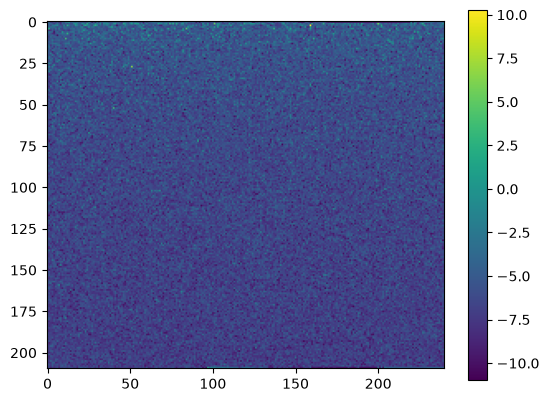

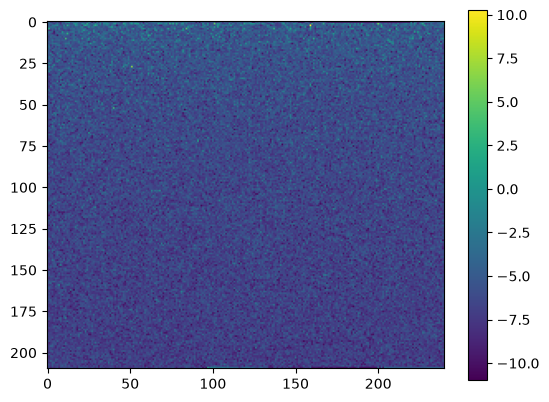

In [61]:
import matplotlib.pyplot as plt

plt.imshow(ours["logits"][0, 3, :50400].reshape(210, -1))
plt.colorbar()
plt.show()

plt.imshow(theirs["logits"][0, 3, :50400].reshape(210, -1))
plt.colorbar()
plt.show()